# Notebook 02 — Preprocesamiento y selección de variables

**Qué hace este notebook:** define cómo se preparan los datos **sin fuga de información (data leakage)** y deja un preprocesador reutilizable (`src/preprocesamiento.py`) que usan los notebooks 03 y 04. Cada decisión se justifica con lo encontrado en el EDA.

**La regla central del enunciado:** *toda transformación que aprenda de los datos (escalado, codificación, selección de variables, umbrales) se ajusta solo con el conjunto de entrenamiento y luego se aplica a validación/prueba.*

In [1]:
import warnings
warnings.filterwarnings('ignore')
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Rutas del proyecto (los notebooks viven en evaluacion 4/notebooks)
RAIZ = Path('..').resolve()
DATOS = RAIZ / 'data' / 'online_shoppers_intention.csv'
FIG = RAIZ / 'figuras'
RES = RAIZ / 'resultados'
FIG.mkdir(exist_ok=True)
RES.mkdir(exist_ok=True)

# Estilo comun a todos los graficos del proyecto
sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams.update({'figure.figsize': (9, 4.5), 'axes.titleweight': 'bold',
                     'axes.spines.top': False, 'axes.spines.right': False})
AZUL, NARANJA, GRIS, VERDE, ROJO = '#1F4E79', '#E8833A', '#8C8C8C', '#3B8E5A', '#C0392B'
pd.set_option('display.max_columns', 50)
pd.set_option('display.float_format', lambda x: f'{x:,.3f}')

sys.path.insert(0, str(RAIZ / 'src'))
from preprocesamiento import (cargar_datos, dividir_train_test, construir_preprocesador, matriz_conducta,
                              NUMERICAS, CATEGORICAS, BINARIAS, CONDUCTA, OBJETIVO, SEMILLA, MESES_ORDEN)

## 1. Decisiones de preprocesamiento

| # | Decisión | Por qué (evidencia del EDA) |
|---|---|---|
| D1 | **Eliminar las 125 sesiones duplicadas exactas** *antes* de dividir | Si un duplicado cae en train y otro en test, el modelo "ve" la respuesta (fuga). Además inflan el conjunto |
| D2 | **División estratificada 80/20** con semilla fija | La compra es solo ~15,6 %: sin estratificar, el test podría tener muy pocos casos positivos |
| D3 | **`log1p` en las 10 variables numéricas** | Asimetría fuerte y muchos ceros (EDA 5.2); `log1p` mantiene el 0 y reduce la cola |
| D4 | **Estandarizar** (media 0, desv. 1) las numéricas | Necesario para regresión logística y para el agrupamiento por distancias; inocuo para los árboles |
| D5 | **One-hot** para `Month`, `VisitorType`, `OperatingSystems`, `Browser`, `Region`, `TrafficType` | Son **códigos sin orden**: tratarlos como números le diría al modelo que Browser 8 > Browser 2 |
| D6 | `handle_unknown='ignore'` | Si en test aparece una categoría que no existía en train, no rompe el modelo |
| D7 | **No hay imputación** | El dataset no tiene valores faltantes (EDA 3) |
| D8 | **No eliminar atípicos** | Las colas largas son sesiones reales (visitantes muy activos); `log1p` las controla |
| D9 | **Manejar `PageValues` de forma explícita** (con y sin) | Posible fuga de información (ver EDA 3); se mide su efecto en el notebook 03 |
| D10 | **El desbalance se trata dentro del modelo** (`class_weight`) y con el **umbral de decisión**, no remuestreando | Remuestrear antes de dividir causa fuga; con `class_weight` el pipeline sigue siendo limpio |

## 2. Carga y división estratificada
Las funciones viven en `src/preprocesamiento.py` para que **todos los notebooks usen exactamente la misma división** (misma semilla).

In [2]:
df_crudo = cargar_datos(quitar_duplicados=False)
df = cargar_datos(quitar_duplicados=True)
print(f'Sesiones originales: {len(df_crudo):,} | sin duplicados: {len(df):,} (D1 elimino {len(df_crudo) - len(df)})')

X_train, X_test, y_train, y_test = dividir_train_test(df)
tabla = pd.DataFrame({
    'sesiones': [len(X_train), len(X_test)],
    'compras': [int(y_train.sum()), int(y_test.sum())],
    'tasa de compra': [y_train.mean(), y_test.mean()],
}, index=['train (80 %)', 'test (20 %)'])
tabla

Sesiones originales: 12,330 | sin duplicados: 12,205 (D1 elimino 125)


,sesiones,compras,tasa de compra
train (80 %),9764,1526,0.156
test (20 %),2441,382,0.156


La división conserva la proporción de compra (**15,6 %** en train y en test): **9.764 sesiones de entrenamiento (1.526 compras)** y **2.441 de prueba (382 compras)**. Con 382 positivos en test, los intervalos de confianza de las métricas serán anchos (±4–5 puntos en el recall): hay que leer las diferencias pequeñas entre modelos con cautela.

## 3. El preprocesador (ColumnTransformer)

In [3]:
prep = construir_preprocesador(incluir_page_values=True)
prep.fit(X_train)                                  # SOLO con entrenamiento
Xt_train = prep.transform(X_train)
Xt_test = prep.transform(X_test)                   # el test solo se TRANSFORMA

nombres = prep.get_feature_names_out()
print(f'Variables originales: {X_train.shape[1]} -> columnas tras el preprocesamiento: {Xt_train.shape[1]}')
print('Ejemplo de columnas:', list(nombres[:12]), '...')
pd.DataFrame(Xt_train[:5, :10], columns=nombres[:10])

Variables originales: 17 -> columnas tras el preprocesamiento: 73
Ejemplo de columnas: ['Administrative', 'Administrative_Duration', 'Informational', 'Informational_Duration', 'ProductRelated', 'ProductRelated_Duration', 'BounceRates', 'ExitRates', 'PageValues', 'SpecialDay', 'Month_Aug', 'Month_Dec'] ...


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay
0,1.611,1.263,0.910,-0.466,0.769,0.475,-0.462,-0.831,2.376,-0.319
1,-0.932,-0.984,-0.481,-0.466,0.474,0.396,-0.462,-0.766,2.307,-0.319
2,-0.932,-0.984,-0.481,-0.466,-0.241,0.009,-0.462,-0.281,-0.495,3.628
3,0.340,0.584,-0.481,-0.466,-1.003,0.153,-0.462,-0.273,-0.495,-0.319
4,-0.932,-0.984,-0.481,-0.466,-0.066,0.689,-0.462,-0.625,-0.495,-0.319


In [4]:
# Comprobacion anti-fuga: el escalador aprendio SOLO de train
num_train = Xt_train[:, :len(NUMERICAS)]
num_test = Xt_test[:, :len(NUMERICAS)]
comprobacion = pd.DataFrame({
    'media en train': num_train.mean(axis=0),
    'desv. en train': num_train.std(axis=0),
    'media en test': num_test.mean(axis=0),
    'desv. en test': num_test.std(axis=0),
}, index=NUMERICAS)
comprobacion

,media en train,desv. en train,media en test,desv. en test
Administrative,-0.000,1.000,-0.000,0.997
Administrative_Duration,0.000,1.000,-0.002,0.994
Informational,-0.000,1.000,-0.005,0.994
Informational_Duration,-0.000,1.000,0.012,1.012
ProductRelated,-0.000,1.000,0.004,0.985
ProductRelated_Duration,-0.000,1.000,-0.010,1.003
BounceRates,-0.000,1.000,0.009,1.003
ExitRates,0.000,1.000,-0.000,1.002
PageValues,-0.000,1.000,0.006,1.010
SpecialDay,0.000,1.000,-0.011,0.990


**Cómo se lee esta tabla (la prueba de que no hay fuga):**
- En **train** las variables tienen media **0,000 y desviación 1,000 exactamente**, porque el escalador se ajustó con ellas.
- En **test** las medias son **cercanas a 0 pero no iguales** (entre −0,011 y +0,012) y las desviaciones rondan 1 (0,985 a 1,012). Eso es justo lo esperado: el test se **transformó con la media y desviación de train**, sin "mirar" sus propios datos. Si saliera exactamente 0 y 1, habríamos escalado el test por separado (fuga).
- Tras el preprocesamiento las 17 variables originales se vuelven **73 columnas** (10 numéricas, 62 columnas one-hot y la binaria `Weekend`).

## 4. Selección de variables

Se mira cuánta información aporta cada variable sobre `Revenue` y cuáles son redundantes. **Todo se calcula solo con train** (para no usar el test al elegir variables).

### 4.1 Información mutua con la variable objetivo
La **información mutua** mide cuánto reduce la incertidumbre sobre `Revenue` conocer una variable; a diferencia de la correlación, captura relaciones **no lineales**.

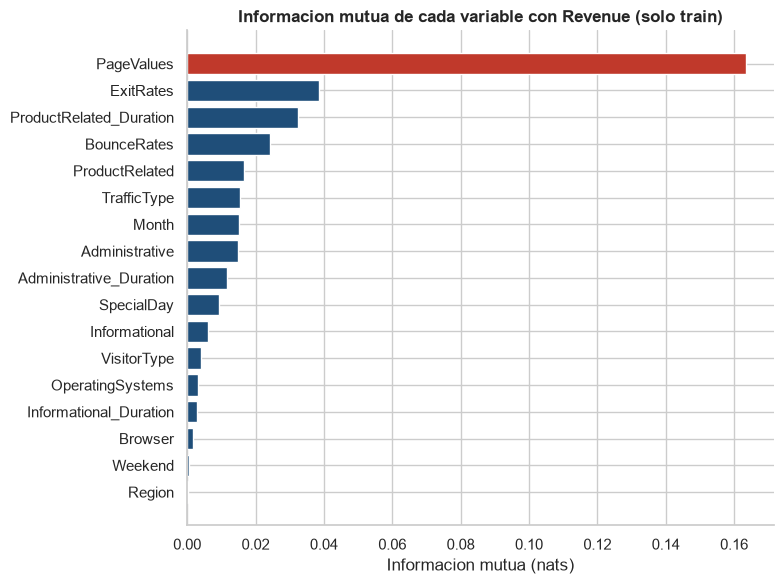

,PageValues,ExitRates,ProductRelated_Duration,BounceRates,ProductRelated,TrafficType,Month,Administrative,Administrative_Duration,SpecialDay,Informational,VisitorType,OperatingSystems,Informational_Duration,Browser,Weekend,Region
informacion mutua,0.164,0.038,0.032,0.024,0.017,0.015,0.015,0.015,0.012,0.009,0.006,0.004,0.003,0.003,0.002,0.000,0.000


In [5]:
from sklearn.feature_selection import mutual_info_classif

cols_modelo = NUMERICAS + CATEGORICAS + BINARIAS
X_mi = X_train[cols_modelo].copy()
discretas = [c in CATEGORICAS + BINARIAS for c in cols_modelo]
for c in CATEGORICAS:
    X_mi[c] = X_mi[c].astype('category').cat.codes
X_mi['Weekend'] = X_mi['Weekend'].astype(int)

mi = mutual_info_classif(X_mi, y_train, discrete_features=discretas, random_state=SEMILLA)
mi = pd.Series(mi, index=cols_modelo).sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(mi.index[::-1], mi.values[::-1], color=[ROJO if c == 'PageValues' else AZUL for c in mi.index[::-1]])
ax.set_title('Informacion mutua de cada variable con Revenue (solo train)')
ax.set_xlabel('Informacion mutua (nats)')
plt.tight_layout()
plt.savefig(FIG / '02_informacion_mutua.png', dpi=150, bbox_inches='tight')
plt.show()
mi.round(4).to_frame('informacion mutua').T

**Lectura de la información mutua**
- **`PageValues` (0,164) aporta más de 4 veces la información de la siguiente** (`ExitRates` 0,038, `ProductRelated_Duration` 0,032, `BounceRates` 0,024). Confirma el hallazgo del EDA.
- `Weekend`, `Region`, `Browser` y `OperatingSystems` aportan información casi nula (≤ 0,003).
- **Decisión:** no se eliminan variables *a mano* por tener poca información (los modelos de árboles y la regularización L2 las ignoran de forma natural y la información mutua con una sola variable no ve interacciones); **sí se tratará `PageValues` como un caso aparte** (con y sin) porque su peso condiciona todo.

### 4.2 Redundancia entre variables
Variables muy correlacionadas aportan casi lo mismo y, en modelos lineales, inestabilizan los coeficientes (**multicolinealidad**). Se calcula el **VIF** (factor de inflación de la varianza) sobre las numéricas transformadas.

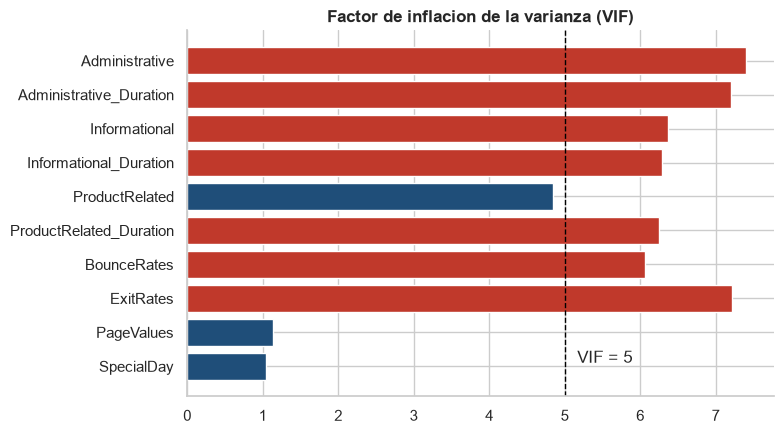

,Administrative,ExitRates,Administrative_Duration,Informational,Informational_Duration,ProductRelated_Duration,BounceRates,ProductRelated,PageValues,SpecialDay
VIF,7.400,7.210,7.200,6.370,6.290,6.240,6.060,4.850,1.130,1.040


In [6]:
from statsmodels.stats.outliers_influence import variance_inflation_factor

Xn = pd.DataFrame(np.log1p(X_train[NUMERICAS]))
Xn = (Xn - Xn.mean()) / Xn.std()
Xn.insert(0, 'const', 1.0)
vif = pd.Series([variance_inflation_factor(Xn.values, i) for i in range(1, Xn.shape[1])], index=NUMERICAS)

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.barh(vif.index[::-1], vif.values[::-1], color=[ROJO if v > 5 else AZUL for v in vif.values[::-1]])
ax.axvline(5, color='black', ls='--', lw=1); ax.text(5.1, 0, ' VIF = 5', va='bottom')
ax.set_title('Factor de inflacion de la varianza (VIF)')
plt.tight_layout()
plt.savefig(FIG / '02_vif.png', dpi=150, bbox_inches='tight')
plt.show()
vif.round(2).sort_values(ascending=False).to_frame('VIF').T

**Lectura del VIF** (> 5 sugiere colinealidad preocupante):
- Siete variables superan 5: `Administrative` (7,4), `ExitRates` (7,2), `Administrative_Duration` (7,2), `Informational` (6,4), `Informational_Duration` (6,3), `ProductRelated_Duration` (6,2) y `BounceRates` (6,1). Son justo los pares conteo–duración y rebote–salida detectados en el EDA.
- `PageValues` (1,13) y `SpecialDay` (1,04) son independientes del resto.
- **Decisión:** **no se elimina ninguna variable** porque (1) los VIF son moderados (todos < 8, lejos de 10–20), (2) los árboles no sufren colinealidad y (3) la regresión logística usa regularización L2 por defecto, que la amortigua. Se deja documentado como limitación para interpretar los coeficientes del modelo lineal.

## 5. Reducción de dimensionalidad: PCA

**Objetivo:** (1) entender **cuánta información se conserva** al comprimir las variables y (2) obtener una proyección 2D para visualizar. El PCA se ajusta **solo con train**.

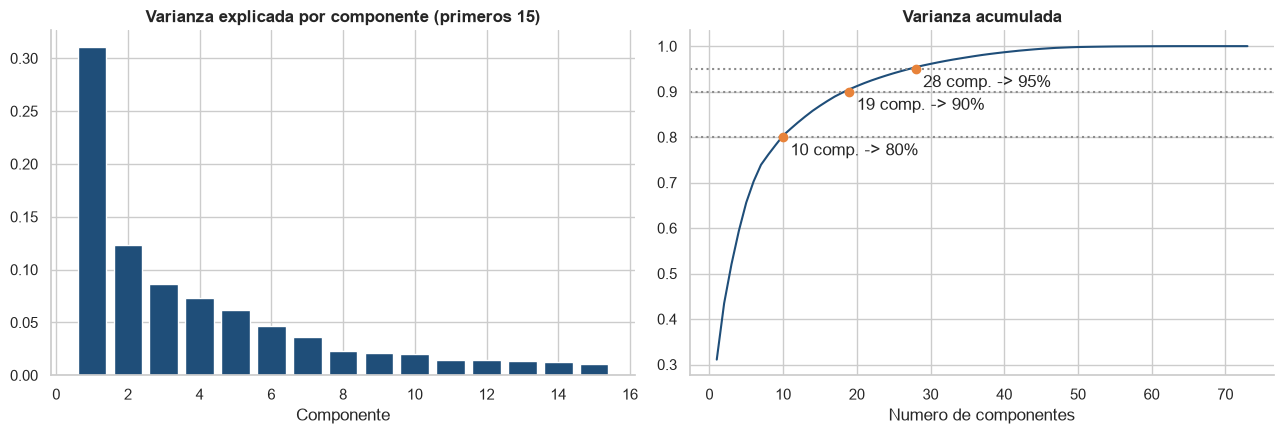

Columnas despues del preprocesamiento: 73
Componentes para conservar 80 %: 10 | 90 %: 19 | 95 %: 28
Los 2 primeros componentes conservan 43.4% de la varianza


In [7]:
from sklearn.decomposition import PCA

pca = PCA(random_state=SEMILLA).fit(Xt_train)
var = pca.explained_variance_ratio_
acum = np.cumsum(var)
n80, n90, n95 = [int(np.argmax(acum >= t) + 1) for t in (.80, .90, .95)]

fig, axs = plt.subplots(1, 2, figsize=(13, 4.5))
axs[0].bar(range(1, 16), var[:15], color=AZUL)
axs[0].set_title('Varianza explicada por componente (primeros 15)'); axs[0].set_xlabel('Componente')
axs[1].plot(range(1, len(acum) + 1), acum, color=AZUL)
for t, n in [(.80, n80), (.90, n90), (.95, n95)]:
    axs[1].axhline(t, color=GRIS, ls=':'); axs[1].plot(n, t, 'o', color=NARANJA)
    axs[1].text(n + 1, t - .04, f'{n} comp. -> {t:.0%}')
axs[1].set_title('Varianza acumulada'); axs[1].set_xlabel('Numero de componentes')
plt.tight_layout()
plt.savefig(FIG / '02_pca_varianza.png', dpi=150, bbox_inches='tight')
plt.show()
print(f'Columnas despues del preprocesamiento: {Xt_train.shape[1]}')
print(f'Componentes para conservar 80 %: {n80} | 90 %: {n90} | 95 %: {n95}')
print(f'Los 2 primeros componentes conservan {acum[1]:.1%} de la varianza')

In [8]:
# Que variables pesan en los 2 primeros componentes? (solo las 6 de mayor peso de cada uno)
cargas = pd.DataFrame(pca.components_[:2].T, index=nombres, columns=['PC1', 'PC2'])
top = pd.concat([cargas['PC1'].abs().nlargest(6).index.to_series(), cargas['PC2'].abs().nlargest(6).index.to_series()]).unique()
cargas.loc[top].round(3)

,PC1,PC2
ProductRelated_Duration,0.400,-0.246
ProductRelated,0.383,-0.099
ExitRates,-0.382,0.372
Administrative,0.348,0.205
Administrative_Duration,0.345,0.179
BounceRates,-0.328,0.420
Informational,0.274,0.519
Informational_Duration,0.274,0.515


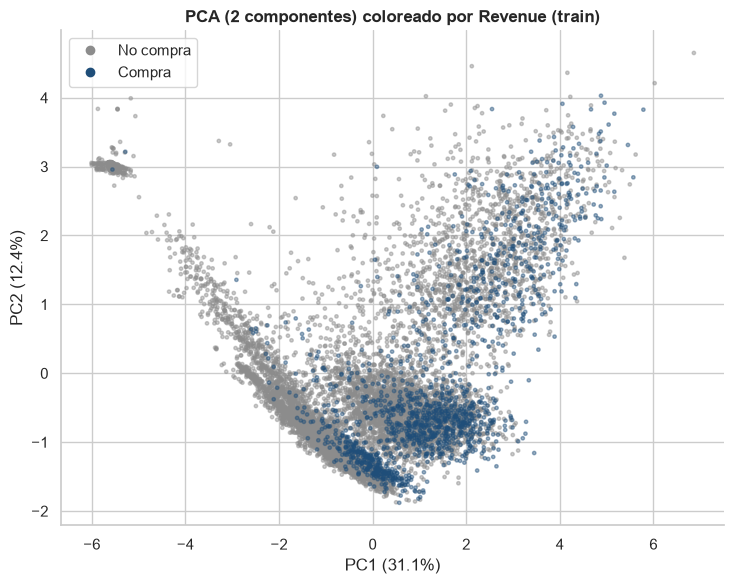

In [9]:
Z = pca.transform(Xt_train)[:, :2]
fig, ax = plt.subplots(figsize=(7.5, 6))
orden = np.argsort(y_train.values)                      # primero las "no compra", encima las "compra"
ax.scatter(Z[orden, 0], Z[orden, 1], c=np.where(y_train.values[orden] == 1, AZUL, GRIS), s=6, alpha=.45)
ax.set_title('PCA (2 componentes) coloreado por Revenue (train)')
ax.set_xlabel(f'PC1 ({var[0]:.1%})'); ax.set_ylabel(f'PC2 ({var[1]:.1%})')
from matplotlib.lines import Line2D
ax.legend(handles=[Line2D([], [], marker='o', ls='', color=GRIS, label='No compra'),
                   Line2D([], [], marker='o', ls='', color=AZUL, label='Compra')])
plt.tight_layout()
plt.savefig(FIG / '02_pca_revenue.png', dpi=150, bbox_inches='tight')
plt.show()

**Información que se conserva y que se pierde con PCA**
- Con las 73 columnas hacen falta **10 componentes para conservar el 80 %** de la varianza, **19 para el 90 %** y **28 para el 95 %**. Los 2 primeros componentes conservan solo el **43,4 %**.
- Es poca compresión porque las columnas *one-hot* reparten la varianza en muchas dimensiones casi independientes.
- **PC1 es un eje de "nivel de actividad"**: carga positivo en páginas y duraciones de producto y administrativas, y negativo en `ExitRates` y `BounceRates` (sesiones largas y comprometidas frente a sesiones cortas que se van). **PC2 contrasta las páginas informativas con las tasas de rebote y salida**.
- En el gráfico por `Revenue` las sesiones con compra **no se separan en dos nubes**: están mezcladas con las de no compra. La compra no se ve como estructura global en 2D; hace falta un modelo supervisado.

## 6. Decisión final sobre variables y dimensionalidad


| Pregunta | Decisión | Justificación |
|---|---|---|
| ¿Se usa PCA como entrada de los modelos? | **No** | 10 componentes solo conservan 80 % y se perdería la interpretación por variable; los modelos manejan sin problema 73 columnas con 9.764 sesiones |
| ¿Se usa PCA en el proyecto? | **Sí, para visualizar** (notebooks 02 y 04) | Sirve para ver la estructura en 2D y se complementa con t-SNE |
| ¿Se eliminan variables por baja información o por VIF alto? | **No** | Los modelos con regularización o árboles las manejan; mejor evaluar su aporte con la importancia por permutación (notebook 03) |
| ¿Se conserva `PageValues`? | **Sí, con ablación** | Es la variable más informativa pero tiene riesgo de fuga; se reporta el desempeño con y sin ella |
| ¿Qué variables van a cada componente? | **Supervisado:** las 17 (con y sin `PageValues`). **No supervisado:** solo 8 variables de conducta (sin `PageValues` ni `SpecialDay`, ni categóricas) | El agrupamiento por distancias necesita variables numéricas comparables y que describan la navegación, no el resultado |